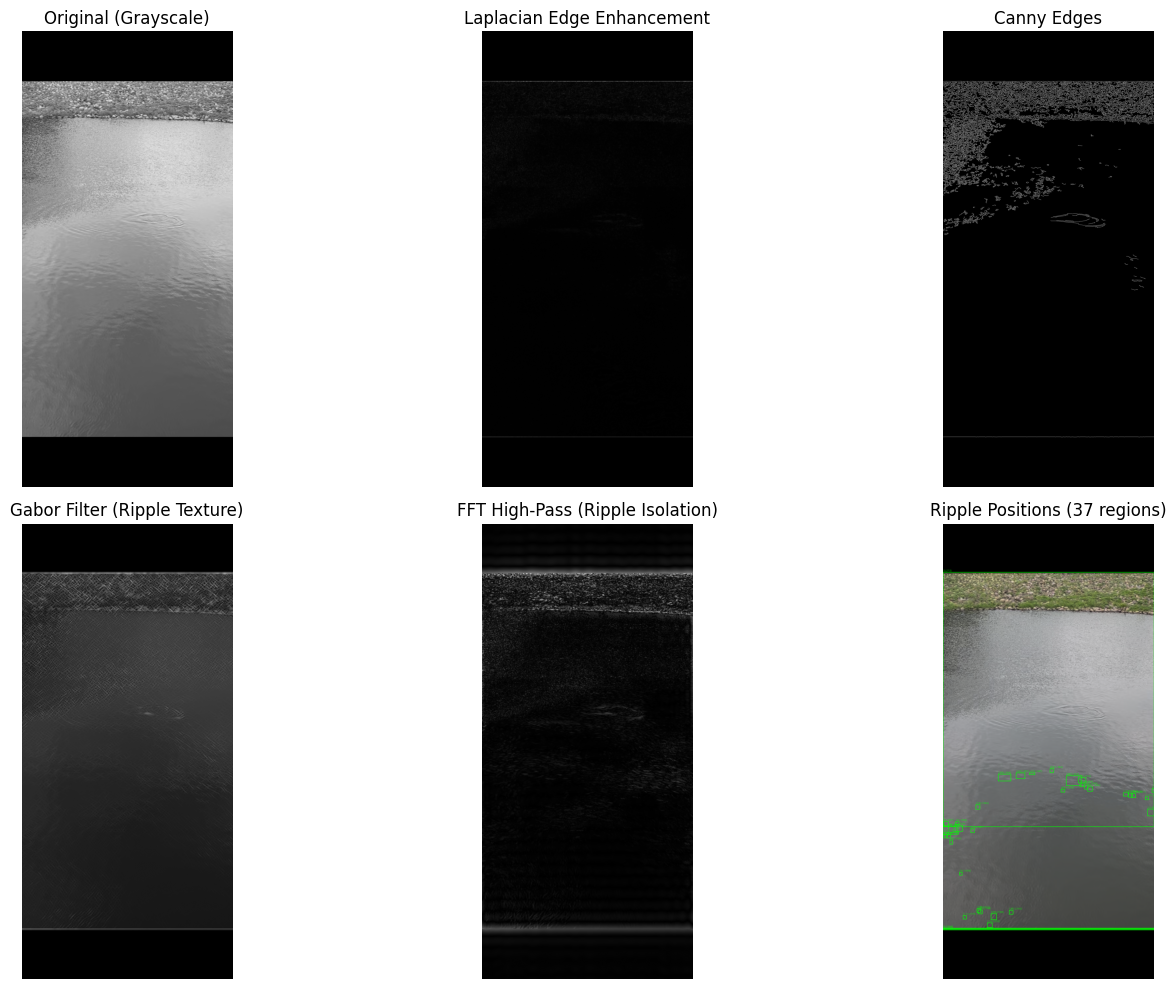

Found 37 ripple regions:
  1. pos=(0,2255)  size=1170x4
  2. pos=(0,2249)  size=1170x4
  3. pos=(245,2220)  size=28x26
  4. pos=(111,2179)  size=18x20
  5. pos=(266,2169)  size=31x33
  6. pos=(367,2150)  size=21x22
  7. pos=(194,2148)  size=23x22
  8. pos=(188,2141)  size=20x21
  9. pos=(91,1939)  size=15x16
  10. pos=(38,1760)  size=15x23


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

pic = cv2.imread("../data/ripple1.PNG")
gray = cv2.cvtColor(pic, cv2.COLOR_BGR2GRAY)

# --- 1. Laplacian edge enhancement (highlights ripple texture) ---
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian_abs = np.uint8(np.abs(laplacian))

# --- 2. Canny edge detection (ripple outlines) ---
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
canny = cv2.Canny(blurred, 30, 100)

# --- 3. Gabor filter (best for directional ripple texture) ---
def build_gabor(ksize, sigma, theta, lam, gamma):
    kernel = cv2.getGaborKernel(
        (ksize, ksize), sigma, theta, lam, gamma, psi=0, ktype=cv2.CV_32F
    )
    return kernel

# try multiple orientations for ripple patterns
gabor_responses = []
for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    kernel = build_gabor(ksize=21, sigma=5, theta=theta, lam=10, gamma=0.5)
    filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)
    gabor_responses.append(filtered)
gabor_combined = np.max(np.abs(gabor_responses), axis=0)
gabor_combined = np.uint8(cv2.normalize(gabor_combined, None, 0, 255, cv2.NORM_MINMAX))

# --- 4. Find ripple positions via contour detection ---
_, thresh = cv2.threshold(gabor_combined, 40, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
ripple_positions = []
contour_frame = pic.copy()
for cnt in contours:
    area = cv2.contourArea(cnt)
    if area > 50:  # filter noise
        x, y, w, h = cv2.boundingRect(cnt)
        ripple_positions.append((x, y, w, h))
        cv2.rectangle(contour_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(contour_frame, f"({x},{y})", (x, y - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

# --- 5. FFT high-pass filter to isolate fine texture ---
f = np.fft.fft2(gray)
fshift = np.fft.fftshift(f)
rows, cols = gray.shape
crow, ccol = rows // 2, cols // 2
mask = np.ones((rows, cols), np.uint8)
mask[crow-20:crow+20, ccol-20:ccol+20] = 0  # block low freq
fshift_filtered = fshift * mask
f_ishift = np.fft.ifftshift(fshift_filtered)
img_back = np.abs(np.fft.ifft2(f_ishift))
img_back = np.uint8(cv2.normalize(img_back, None, 0, 255, cv2.NORM_MINMAX))

# --- Display results ---
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Original (Grayscale)")
axes[0, 0].axis("off")

axes[0, 1].imshow(laplacian_abs, cmap="gray")
axes[0, 1].set_title("Laplacian Edge Enhancement")
axes[0, 1].axis("off")

axes[0, 2].imshow(canny, cmap="gray")
axes[0, 2].set_title("Canny Edges")
axes[0, 2].axis("off")

axes[1, 0].imshow(gabor_combined, cmap="gray")
axes[1, 0].set_title("Gabor Filter (Ripple Texture)")
axes[1, 0].axis("off")

axes[1, 1].imshow(img_back, cmap="gray")
axes[1, 1].set_title("FFT High-Pass (Ripple Isolation)")
axes[1, 1].axis("off")

axes[1, 2].imshow(cv2.cvtColor(contour_frame, cv2.COLOR_BGR2RGB))
axes[1, 2].set_title(f"Ripple Positions ({len(ripple_positions)} regions)")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

print(f"Found {len(ripple_positions)} ripple regions:")
for i, (x, y, w, h) in enumerate(ripple_positions[:10]):
    print(f"  {i+1}. pos=({x},{y})  size={w}x{h}")


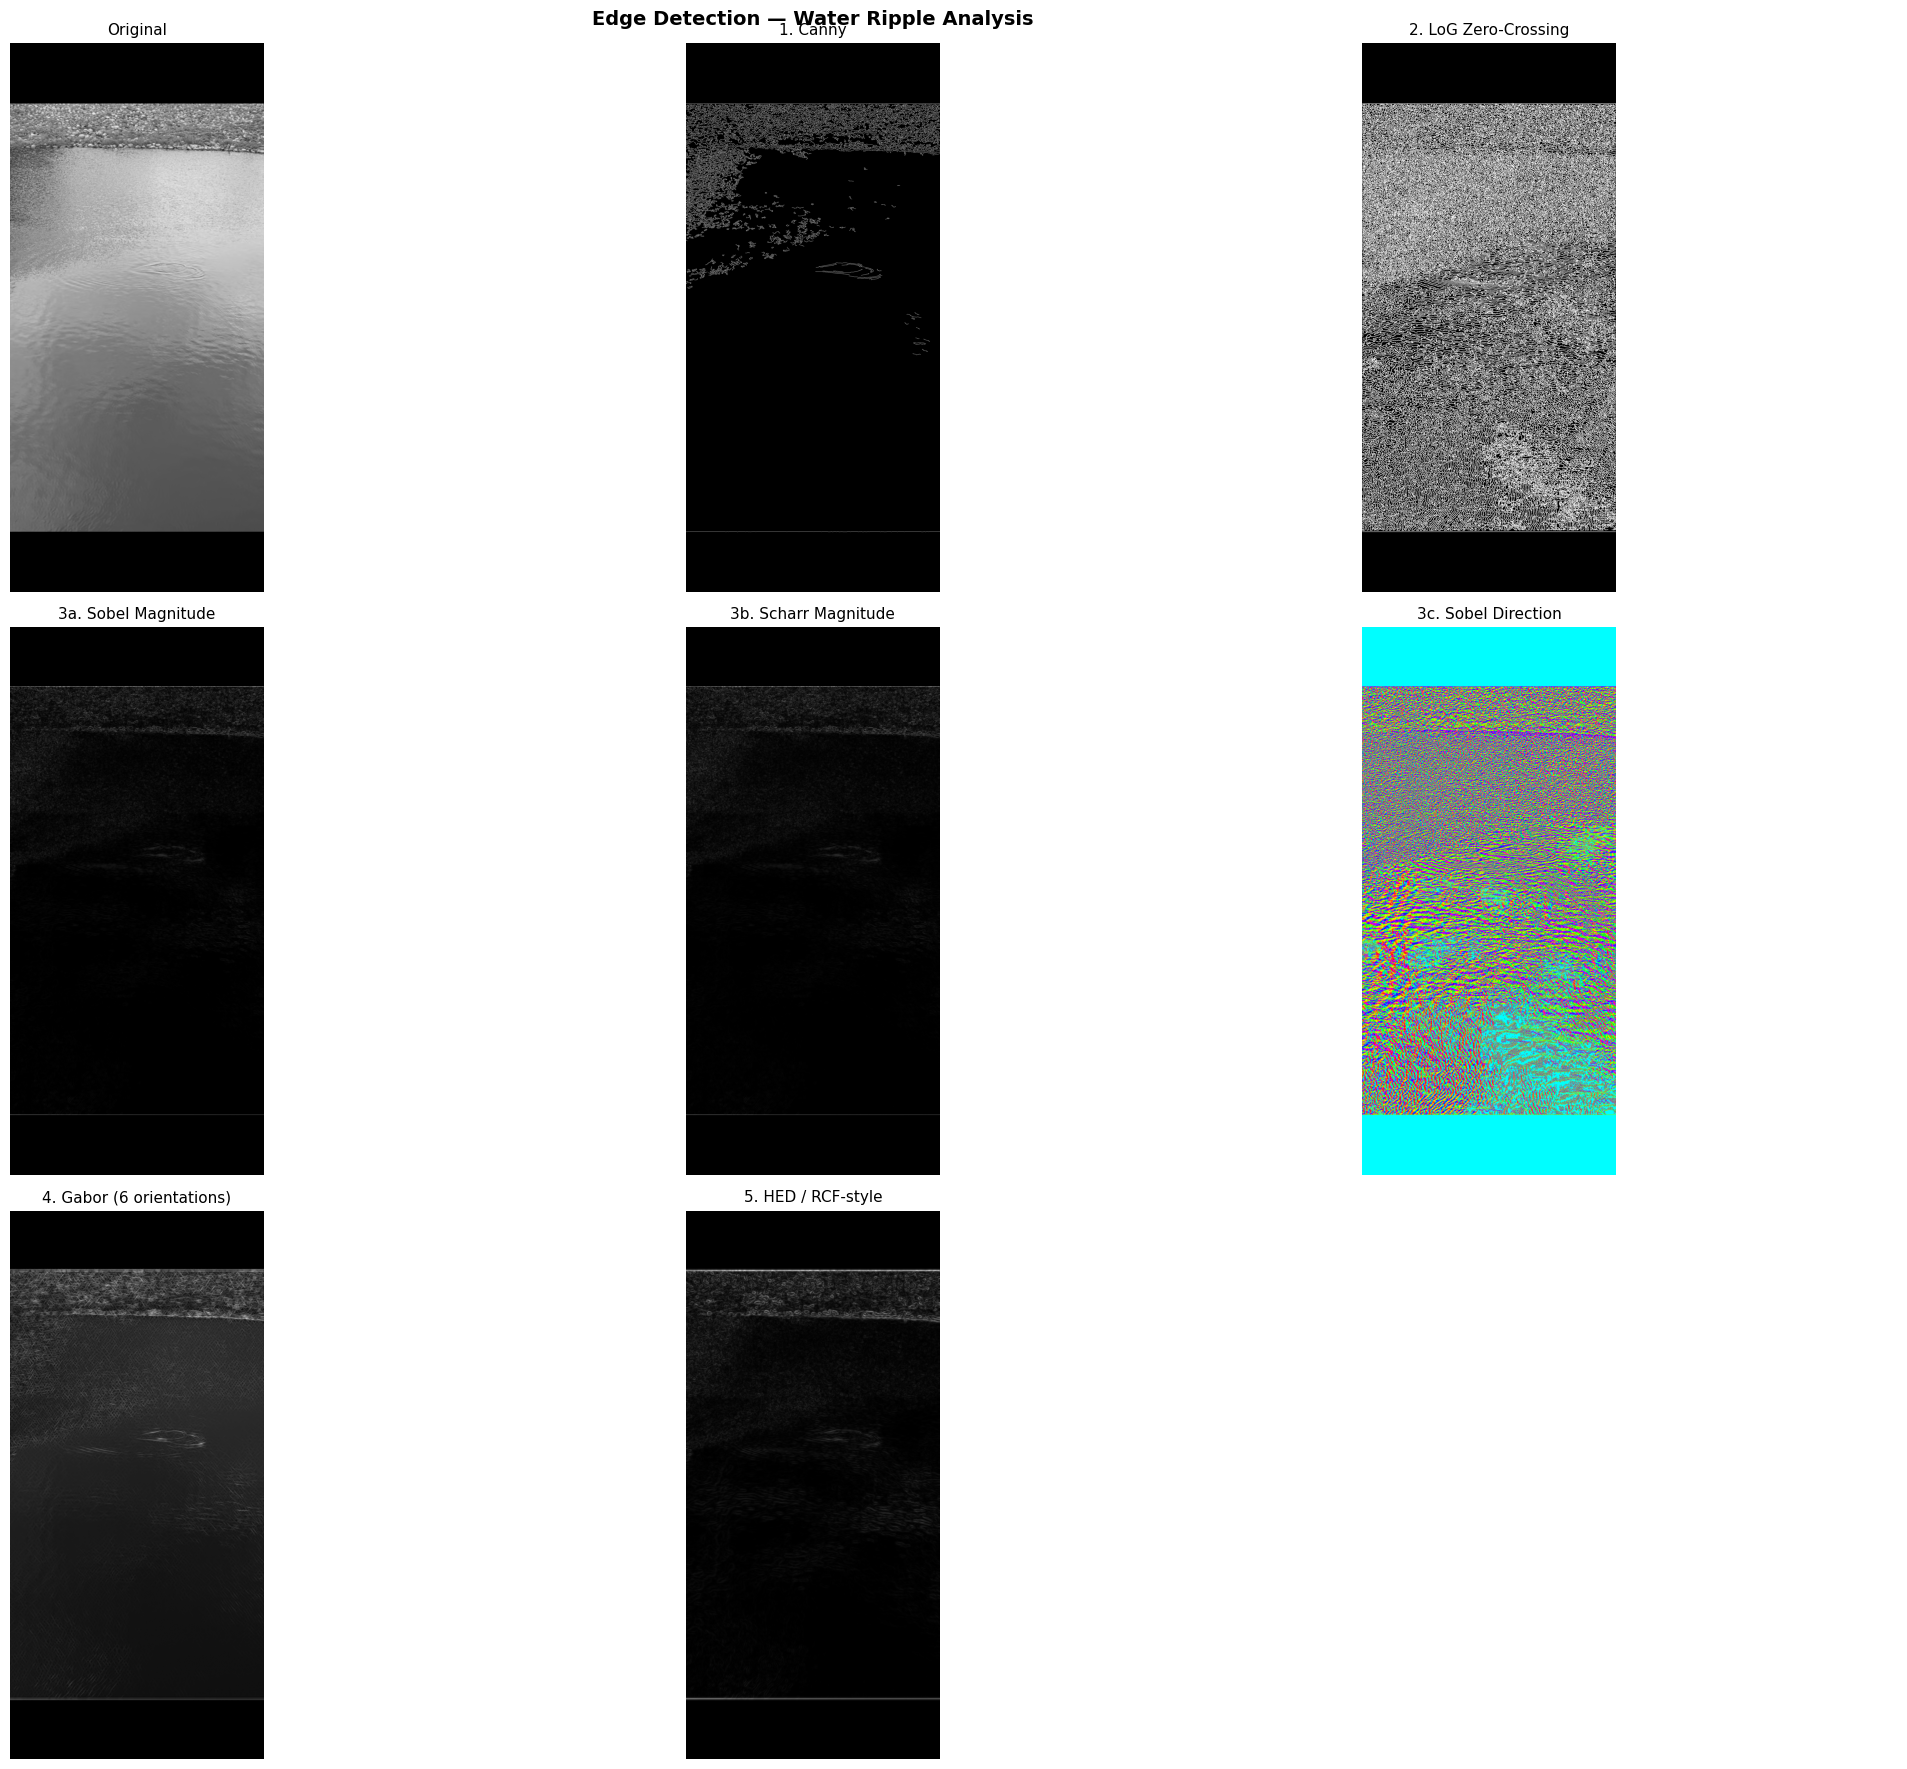

Algorithm         | Ripple Suitability
--------------------------------------------------------
Canny             | Good — clean binary edges, fast
LoG               | Best — scale-space, smooth ripples
Sobel / Scharr    | Decent — magnitude + direction info
Gabor             | Excellent — directional wave texture
HED / RCF         | Best — learned multi-scale edges
--------------------------------------------------------
For water ripples, LoG (smooth continuous edges)
and Gabor (directional wave texture) are top choices.
HED model not found; used multi-scale Sobel fallback.
To use real HED, download:
  http://vcl.ucsd.edu/hed/hed_pretrained_bsds.caffemodel


In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import os

pic = cv2.imread("../data/ripple1.PNG")
gray = cv2.cvtColor(pic, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

# ========================================================
# 1. Canny
# ========================================================
canny = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 30, 100)

# ========================================================
# 2. Laplacian of Gaussian (LoG)
# ========================================================
log_gauss = ndimage.gaussian_filter(gray.astype(np.float64), sigma=2.0)
log_lap = ndimage.laplace(log_gauss)
log_zc = np.zeros_like(log_lap, dtype=np.uint8)
for i in range(1, h - 1):
    for j in range(1, w - 1):
        p = log_lap[i-1:i+2, j-1:j+2]
        if p.min() < 0 and p.max() > 0:
            log_zc[i, j] = 255

# ========================================================
# 3. Sobel & Scharr
# ========================================================
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)
sobel_mag = np.uint8(cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX))

scharr_x = cv2.Scharr(gray, cv2.CV_64F, 1, 0)
scharr_y = cv2.Scharr(gray, cv2.CV_64F, 0, 1)
scharr_mag = np.sqrt(scharr_x**2 + scharr_y**2)
scharr_mag = np.uint8(cv2.normalize(scharr_mag, None, 0, 255, cv2.NORM_MINMAX))

# Sobel direction
sobel_angle = np.arctan2(sobel_y, sobel_x)
sobel_hsv = np.zeros((h, w, 3), dtype=np.uint8)
sobel_hsv[..., 1] = 255
sobel_hsv[..., 0] = (sobel_angle + np.pi) * 180 / np.pi / 2
sobel_hsv[..., 2] = 255
sobel_dir = cv2.cvtColor(sobel_hsv, cv2.COLOR_HSV2BGR)

# ========================================================
# 4. Gabor filter bank (6 orientations)
# ========================================================
gabor_responses = []
for theta in np.linspace(0, np.pi, 6):
    kernel = cv2.getGaborKernel((21, 21), 5, theta, 10, 0.5, psi=0, ktype=cv2.CV_32F)
    filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)
    gabor_responses.append(filtered)
gabor_mag = np.max(np.abs(gabor_responses), axis=0)
gabor_img = np.uint8(cv2.normalize(gabor_mag, None, 0, 255, cv2.NORM_MINMAX))

# ========================================================
# 5. HED / RCF-style multi-scale edge detection
# ========================================================
hed_model = "hed_pretrained_bsds.caffemodel"
hed_proto = "deploy.prototxt"
hed_fallback = True
if os.path.exists(hed_model) and os.path.exists(hed_proto):
    net = cv2.dnn.readNetFromCaffe(hed_proto, hed_model)
    blob = cv2.dnn.blobFromImage(pic, scalefactor=1.0, size=(500, 500),
                                 mean=(104.00698793, 116.66876762, 122.67891434),
                                 swapRB=False, crop=False)
    net.setInput(blob)
    hed_out = net.forward()
    hed_img = np.uint8(cv2.resize(hed_out[0, 0] * 255, (w, h)))
    hed_fallback = False
else:
    # RCF-style: weighted multi-scale Sobel
    edges = np.zeros((h, w), dtype=np.float32)
    for s in [1.0, 2.0, 4.0]:
        sz = int(s * 3) | 1
        gauss = ndimage.gaussian_filter(gray.astype(np.float32), sigma=s)
        sx = cv2.Sobel(gauss, cv2.CV_32F, 1, 0, ksize=sz)
        sy = cv2.Sobel(gauss, cv2.CV_32F, 0, 1, ksize=sz)
        mag = cv2.normalize(np.sqrt(sx**2 + sy**2), None, 0, 1, cv2.NORM_MINMAX)
        edges += mag
    hed_img = np.uint8(cv2.normalize(edges, None, 0, 255, cv2.NORM_MINMAX))

# ========================================================
# Display: 3 x 3
# ========================================================
titles = [
    "Original", "1. Canny", "2. LoG Zero-Crossing",
    "3a. Sobel Magnitude", "3b. Scharr Magnitude", "3c. Sobel Direction",
    "4. Gabor (6 orientations)", "5. HED / RCF-style", ""
]
images = [
    gray, canny, log_zc,
    sobel_mag, scharr_mag, cv2.cvtColor(sobel_dir, cv2.COLOR_BGR2RGB),
    gabor_img, hed_img, np.zeros((1, 1))
]
cmaps = ["gray", "gray", "gray", "gray", "gray", None, "gray", "gray", None]

fig, axes = plt.subplots(3, 3, figsize=(22, 18))
for idx, ax in enumerate(axes.flat):
    if idx >= len(images) - 1:
        ax.axis("off")
        continue
    if cmaps[idx]:
        ax.imshow(images[idx], cmap=cmaps[idx])
    else:
        ax.imshow(images[idx])
    ax.set_title(titles[idx], fontsize=11)
    ax.axis("off")

plt.suptitle("Edge Detection — Water Ripple Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("=" * 56)
print("Algorithm         | Ripple Suitability")
print("-" * 56)
print("Canny             | Good — clean binary edges, fast")
print("LoG               | Best — scale-space, smooth ripples")
print("Sobel / Scharr    | Decent — magnitude + direction info")
print("Gabor             | Excellent — directional wave texture")
print("HED / RCF         | Best — learned multi-scale edges")
print("-" * 56)
print("For water ripples, LoG (smooth continuous edges)")
print("and Gabor (directional wave texture) are top choices.")
if hed_fallback:
    print("HED model not found; used multi-scale Sobel fallback.")
    print("To use real HED, download:")
    print("  http://vcl.ucsd.edu/hed/hed_pretrained_bsds.caffemodel")


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Video, display

cap = cv2.VideoCapture("../data/fish_ripple.mov")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"Video: {total_frames} frames, {w}x{h} @ {fps:.1f} FPS")

# Output video: original + flow overlay side by side
out_path = "../data/ripple_optical_flow.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_w = w * 2
out = cv2.VideoWriter(out_path, fourcc, fps, (out_w, h))

ret, prev = cap.read()
if not ret:
    raise RuntimeError("Cannot read video")

prev_gray = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)
frame_count = 0

while True:
    ret, nxt = cap.read()
    if not ret:
        break
    next_gray = cv2.cvtColor(nxt, cv2.COLOR_BGR2GRAY)

    # Dense optical flow (Farneback)
    flow = cv2.calcOpticalFlowFarneback(
        prev_gray, next_gray, None,
        pyr_scale=0.5, levels=3, winsize=15,
        iterations=3, poly_n=5, poly_sigma=1.2, flags=0
    )

    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    # HSV flow visualization
    hsv = np.zeros_like(prev)
    hsv[..., 1] = 255
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    flow_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # Magnitude heatmap overlay on original
    mag_norm = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    mag_color = cv2.applyColorMap(mag_norm, cv2.COLORMAP_HOT)
    overlay = cv2.addWeighted(prev, 0.5, mag_color, 0.5, 0)

    # Info text
    mean_mag = np.mean(mag)
    active_px = np.sum(mag > 1.0)
    cv2.putText(prev, f"Frame {frame_count}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    cv2.putText(overlay, f"mean flow={mean_mag:.2f}  active={active_px}px", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    # Side-by-side: original | heatmap overlay
    combined = np.hstack((prev, overlay))
    out.write(combined)

    frame_count += 1
    if frame_count % 100 == 0:
        print(f"  processed {frame_count} frames...")

    prev = nxt
    prev_gray = next_gray

cap.release()
out.release()
print(f"Output: {out_path} ({frame_count} frames)")

# Display video inline
display(Video(out_path, width=out_w, embed=True))


Video: 298 frames, 1920x1080 @ 29.0 FPS
  processed 100 frames...
  processed 200 frames...
Output: ../data/ripple_optical_flow.mp4 (288 frames)
